# Phase 5 — Watch the robot learn

Run from the `notebooks/` folder. The first cell makes the project root importable.

In [1]:
import sys, os
sys.path.append("..")          # so `env`, `agents`, `utils` import
os.makedirs("../results", exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, Image

from env.grid_env import GridEnv
from agents.q_learning import QLearningAgent, train, greedy_rollout
from utils.plotting import plot_training
from utils.animate import animate_path, animate_agents
from agents.baselines import RandomAgent, AStarAgent
from evaluation import run_episode, compare, format_table

## 1. Train, recording a few early episodes

In [2]:
env = GridEnv()
agent = QLearningAgent(grid_size=env.size, seed=0)

early = (1, 25, 100)
history = train(env, agent, n_episodes=1000, log_every=100, record_episodes=early)

ep   100 | avg reward  -265.1 | avg steps  118.8 | success   74% | eps 0.606
ep   200 | avg reward    16.6 | avg steps   39.3 | success  100% | eps 0.367
ep   300 | avg reward    59.9 | avg steps   25.7 | success  100% | eps 0.222
ep   400 | avg reward    71.2 | avg steps   22.2 | success  100% | eps 0.135
ep   500 | avg reward    75.1 | avg steps   20.7 | success  100% | eps 0.082
ep   600 | avg reward    78.5 | avg steps   19.6 | success  100% | eps 0.050
ep   700 | avg reward    79.4 | avg steps   19.2 | success  100% | eps 0.050
ep   800 | avg reward    79.6 | avg steps   19.1 | success  100% | eps 0.050
ep   900 | avg reward    80.2 | avg steps   18.9 | success  100% | eps 0.050
ep  1000 | avg reward    80.5 | avg steps   18.8 | success  100% | eps 0.050


## 2. Training curves and the learned path

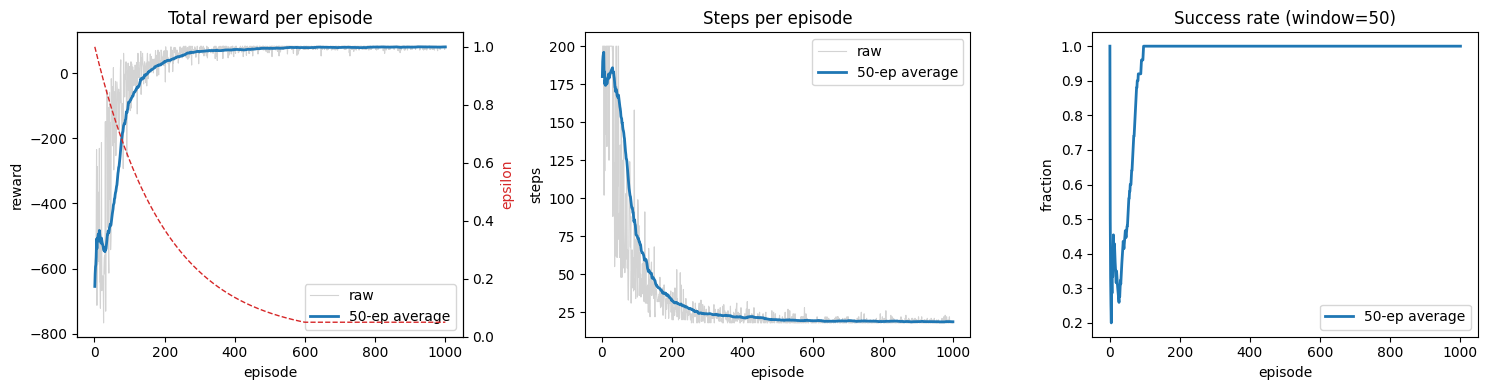

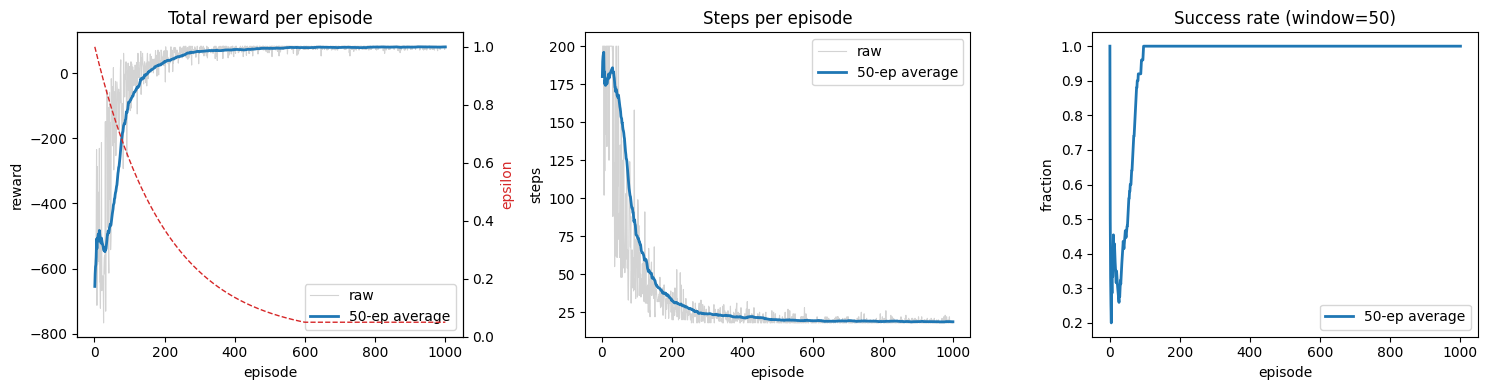

In [3]:
plot_training(history)

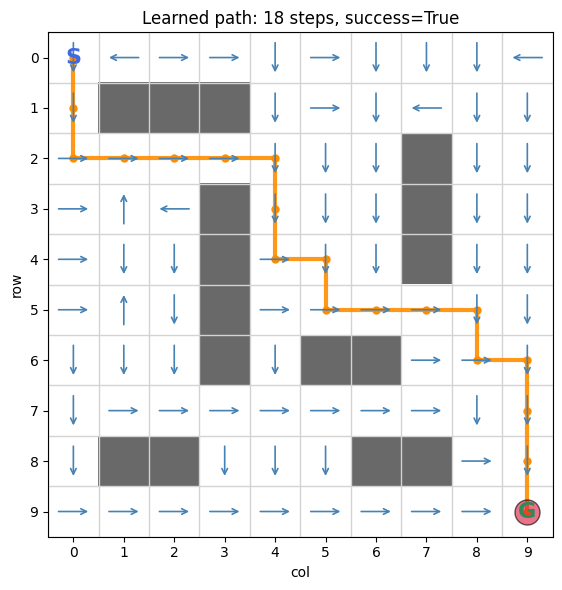

(<Figure size 600x600 with 1 Axes>,
 <Axes: title={'center': 'Learned path: 18 steps, success=True'}, xlabel='col', ylabel='row'>)

In [4]:
policy = agent.Q.argmax(axis=2)
path, success = greedy_rollout(env, agent)
env.render(title=f"Learned path: {len(path) - 1} steps, success={success}",
           path=path, policy=policy)

## 3. The trained robot moving

Option A — save a GIF (works everywhere, including Colab's file browser) and show it inline.

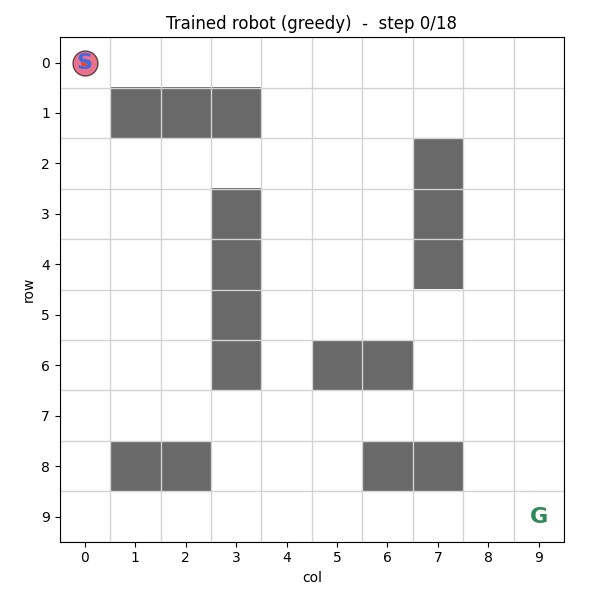

In [5]:
animate_path(env, path, save_path="../results/robot_path.gif", title="Trained robot (greedy)")
Image("../results/robot_path.gif")

Option B — interactive player with play / pause / step controls.

In [6]:
anim = animate_path(env, path, save_path=None, title="Trained robot (greedy)")
HTML(anim.to_jshtml())

## 4. The same robot early in training

Episode 1 is pure random walk (ε = 1). By episode 100, ε ≈ 0.6 and the table already pulls the robot in roughly the right direction. `max_frames=80` keeps the long early episodes watchable.

In [7]:
for ep in early:
    p = history["paths"][ep]
    print(f"episode {ep:3d}: {len(p) - 1:3d} steps, reached goal = {p[-1] == env.goal}, "
          f"eps = {history['epsilon'][ep - 1]:.2f}")

episode   1: 180 steps, reached goal = True, eps = 1.00
episode  25: 200 steps, reached goal = False, eps = 0.89
episode 100:  50 steps, reached goal = True, eps = 0.61


In [8]:
ep = 25     # change to 1 or 100
anim_early = animate_path(env, history["paths"][ep], save_path=None,
                          interval_ms=120, max_frames=80,
                          title=f"Episode {ep}, eps={history['epsilon'][ep - 1]:.2f}")
HTML(anim_early.to_jshtml())

To save any of these as a GIF instead, pass `save_path="../results/episode_025.gif"` and show it with `Image(...)` as in option A.

## 5. Random vs Q-learning vs A*, side by side

Only Q-learning *learned* anything — A* plans from the full map, Random never improves. This runs one greedy episode of each on the same grid and animates them in sync. Finished agents park on the goal while the random one keeps wandering (`max_frames=80` caps the length).

In [9]:
agents = {
    "Random": RandomAgent(seed=0),
    "Q-learning": agent,          # the table we trained above
    "A*": AStarAgent(env),
}

paths = {name: run_episode(env, ag, record_path=True)["path"]
         for name, ag in agents.items()}

for name, p in paths.items():
    print(f"{name:11s}: {len(p) - 1:3d} steps, reached goal = {p[-1] == env.goal}")

Random     : 164 steps, reached goal = True
Q-learning :  18 steps, reached goal = True
A*         :  18 steps, reached goal = True


Option A — save a GIF and show it.

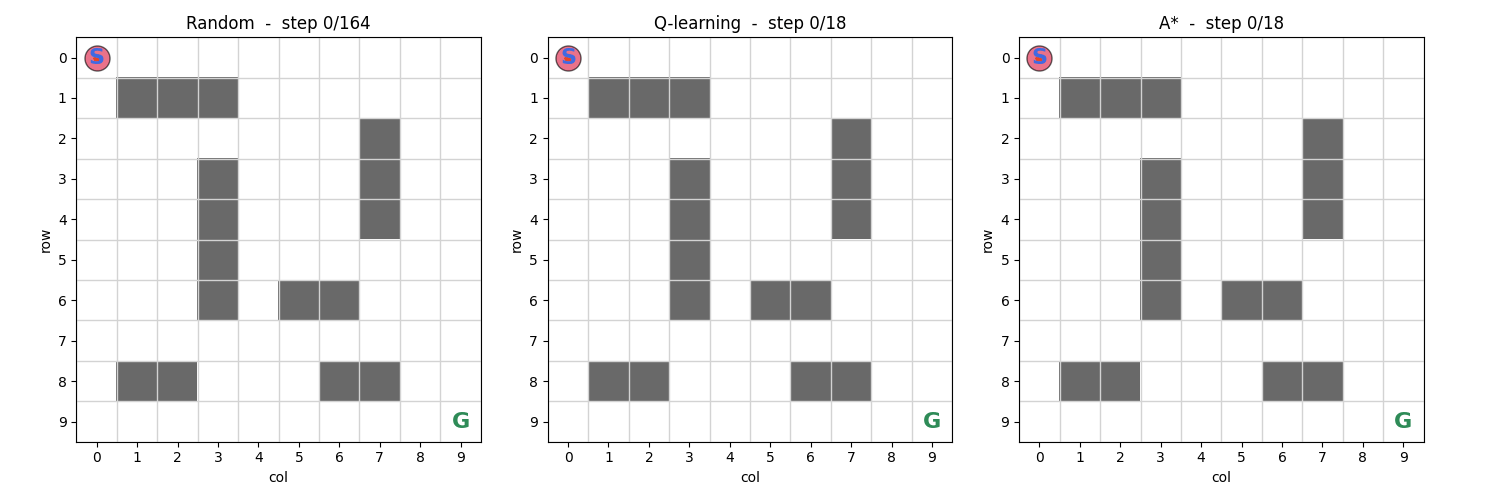

In [10]:
animate_agents(env, paths, save_path="../results/agents_side_by_side.gif")
Image("../results/agents_side_by_side.gif")

Option B — interactive player.

In [11]:
anim_cmp = animate_agents(env, paths, save_path=None)
HTML(anim_cmp.to_jshtml())

Notice that Q-learning and A* both take 18 steps but by different routes. The map has several shortest paths and nothing in the reward prefers one; A* picks by queue order, Q-learning by whichever route got reinforced first.

## 6. The numbers behind the animation

Same three agents, 100 greedy episodes each (this is what `evaluate_agents.py` does).

In [12]:
results = compare(env, agents, n_episodes=100)
print(format_table(results))

| Agent | Success | Avg steps | Avg reward | Avg collisions |
|---|---|---|---|---|
| Random | 16% | 188.4 | -653.2 | 53.4 |
| Q-learning | 100% | 18.0 | 83.0 | 0.0 |
| A* | 100% | 18.0 | 83.0 | 0.0 |
